# Week 6: Supervised Learning Recipe Improvements

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# REMINDER: Google Gemini

Google's Gemini LLM is now embedded into Colab's interface and will suggest context-aware autocompletions for your code, by default. Auto-completion suggestions can sometimes be a useful time-saver, but they can also be distracting and stop you from thinking and learning. **Consider turning Colab's code completion suggestions off if you find this is happening (Tools->Settings->Editor->see checkbox options)**.

# Overview

This notebook divides up between "Better data preparation" techniques (first), and "Better model evaluation" techniques (second).

# Better data preparation (1)

So far on this module we've worked only with clean data, and a single shuffle and split (our "basic" supervised learning recipe). In the following sections we'll introduce techniques for cleaning raw data, and for further improving the way we partition our data and train and evaluate our models.

This material is divided up between "data cleaning" techniques and "data splitting" techniques.

# Data cleaning

## The biopsies_raw.csv data

So far on this module we've worked only with clean data. In these tasks we're going to look at some of the steps typically involved in cleaning data for yourself. We'll work with a raw copy of the biopsies data, which contains some problems: biopsies_raw.csv.



## Pandas is our friend

Recall the Pandas package (and DataFrame type) that we met in the very first lab. The Pandas package has lots of convenient functionality to help us do data cleaning. So we'll stick with Pandas DataFrames for most of our work (we won't convert to NumPy arrays until we're finished cleaning and ready to get on with the rest of the recipe):

In [18]:
# Importing the packages we use
import pandas as pd
import numpy as np

# Loading all the observations (as a Pandas DataFrame)
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies_raw.csv')

### Pandas quickstart

Here's a quick summary of how you access/edit data in a DataFrame. We won't rely heavily on these options in the rest of the notebook - we'll mostly be introducing some useful methods of the DataFrame class that return edited copies of the underlying data - but it's good to be aware of them.

**Run the following code cells and briefly review the outputs against the code comments:**

**Tip**: you should find there is some familiarity from our previous work on accessing NumPy arrays (e.g., in the "slice" notation).

**Tip**: there is lots more to say about DataFrames; we don't need the details on this module, but if you're *interested* then [10 minutes to Pandas](https://pandas.pydata.org/docs/user_guide/10min.html) is good.

In [19]:
# Take a copy of our DataFrame to play around with
observations_play = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies_raw.csv')

In [20]:
# We can access column's by their name (which comes from the first row in the .csv)
print(observations_play['radius_mean'])

0      13.540
1      13.080
2       9.504
3      13.030
4       8.196
        ...  
570    20.920
571    21.560
572    20.130
573    16.600
574    20.600
Name: radius_mean, Length: 575, dtype: float64


In [21]:
# We can access rows using a zero-based index
print(observations_play.iloc[3])

patient_id                 854941.000000
diagnosis                       0.000000
radius_mean                    13.030000
texture_mean                   18.420000
perimeter_mean                 82.610000
area_mean                     523.800000
smoothness_mean                 0.089830
compactness_mean                0.037660
concavity_mean                  0.025620
concave points_mean             0.029230
symmetry_mean                   0.146700
fractal_dimension_mean          0.058630
radius_se                       0.183900
texture_se                      2.342000
perimeter_se                    1.170000
area_se                        14.160000
smoothness_se                   0.004352
compactness_se                  0.004899
concavity_se                    0.013430
concave points_se               0.011640
symmetry_se                     0.026710
fractal_dimension_se            0.001777
radius_worst                   13.300000
texture_worst                  22.810000
perimeter_worst 

In [22]:
# We can use 'slicing' notation similar to what we're used to from NumPy
print(observations_play.iloc[3:5,:])

   patient_id  diagnosis  radius_mean  texture_mean  perimeter_mean  \
3      854941          0       13.030         18.42           82.61   
4    85713702          0        8.196         16.84           51.71   

   area_mean  smoothness_mean  compactness_mean  concavity_mean  \
3      523.8          0.08983           0.03766         0.02562   
4      201.9          0.08600           0.05943         0.01588   

   concave points_mean  ...  radius_worst  texture_worst  perimeter_worst  \
3             0.029230  ...        13.300          22.81            84.46   
4             0.005917  ...         8.964          21.96            57.26   

   area_worst  smoothness_worst  compactness_worst  concavity_worst  \
3       545.9           0.09701            0.04619          0.04833   
4       242.2           0.12970            0.13570          0.06880   

   concave points_worst  symmetry_worst  fractal_dimension_worst  
3               0.05013          0.1987                  0.06169  
4   

In [23]:
# We can edit the dataframe using this approach
observations_play.iloc[3,5] = -99 # a single value
observations_play.iloc[3,1:4] = [50, -99, 70] # multiple values
print(observations_play.iloc[3,:]) # check

patient_id                 854941.000000
diagnosis                      50.000000
radius_mean                   -99.000000
texture_mean                   70.000000
perimeter_mean                 82.610000
area_mean                     -99.000000
smoothness_mean                 0.089830
compactness_mean                0.037660
concavity_mean                  0.025620
concave points_mean             0.029230
symmetry_mean                   0.146700
fractal_dimension_mean          0.058630
radius_se                       0.183900
texture_se                      2.342000
perimeter_se                    1.170000
area_se                        14.160000
smoothness_se                   0.004352
compactness_se                  0.004899
concavity_se                    0.013430
concave points_se               0.011640
symmetry_se                     0.026710
fractal_dimension_se            0.001777
radius_worst                   13.300000
texture_worst                  22.810000
perimeter_worst 

In [24]:
# We can use boolean indexing
print(observations_play[observations_play['radius_mean'] < 8])

     patient_id  diagnosis  radius_mean  texture_mean  perimeter_mean  \
3        854941         50      -99.000         70.00           82.61   
35       862722          0        6.981         13.43           43.79   
335      921092          0        7.729         25.49           47.98   
336      921362          0        7.691         25.44           48.34   
359       92751          0        7.760         24.54           47.92   

     area_mean  smoothness_mean  compactness_mean  concavity_mean  \
3        -99.0          0.08983           0.03766         0.02562   
35       143.5          0.11700           0.07568         0.00000   
335      178.8          0.08098           0.04878         0.00000   
336      170.4          0.08668           0.11990         0.09252   
359      181.0          0.05263           0.04362         0.00000   

     concave points_mean  ...  radius_worst  texture_worst  perimeter_worst  \
3                0.02923  ...        13.300          22.81         

## Printing a summary

We already know the `.shape()` property is useful for printing in our debug (showing us the dimensions of our data structures), but we can also ask Pandas for a quick summary of the data *inside* each column of a  DataFrame using its `.info()` method:

In [25]:
# See a summary of the features and feature values we're working with
print(observations.info())


duplicates = observations.duplicated().sum()
print("Number of duplicate rows:", duplicates)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 575 entries, 0 to 574
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               575 non-null    int64  
 1   diagnosis                575 non-null    int64  
 2   radius_mean              575 non-null    float64
 3   texture_mean             575 non-null    float64
 4   perimeter_mean           575 non-null    float64
 5   area_mean                575 non-null    float64
 6   smoothness_mean          574 non-null    float64
 7   compactness_mean         575 non-null    float64
 8   concavity_mean           575 non-null    float64
 9   concave points_mean      575 non-null    float64
 10  symmetry_mean            575 non-null    float64
 11  fractal_dimension_mean   575 non-null    float64
 12  radius_se                575 non-null    float64
 13  texture_se               575 non-null    float64
 14  perimeter_se             5

## Missing values

Notice a couple of the columns don't have the same number of non-null values as the others: they are missing one or more feature values. This is a common feature of raw data.

You can try to fill in (or "impute") missing feature values based, for example by calculating an average. The DataFrame method `.fillna()` is useful for this kind of operation. However, you have to be careful you don't allow data leakage by accident. (E.g., if you replace a missing value by calculating the average for that feature value across all your observations, and that imputed feature value later ends up in your training data, then it contains some information from your testing data.)

The other issue is that we have no idea, for any given observation, whether it really is safe to make assumptions about missing feature values.

Typically, unless we are able to talk to a domain expert who really understands the data (in the case of the biopsies data, this would be a clinician with the relevant expertise), then the safest thing to do with any observations that are missing feature values is to delete them altogether. That is, delete the whole observation.

We can delete any rows with missing feature values using the DataFrame's `.dropna()` method:

In [26]:
# Delete any observations with missing feature values
observations = observations.dropna()

Add some code to call the DataFrame's `.info()` method again, and confirm there are now the same number of non-null values in every column:

In [27]:
# Add your code on the line below:
observations.isnull().sum()


,0
patient_id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


## Duplicates

The next step is to delete duplicated observations, another common feature of raw data (e.g., two different people log the same observation).

We can do this by calling the DataFrame's `.drop_duplicates()` method:

In [28]:
observations = observations.drop_duplicates()

Add some code to call the DataFrame's `.info()` method again, and confirm how many observations were deleted as duplicates.

The number of duplicate observations deleted was: ** 3**

## Irrelevant features

This is a good moment to think about whether any of the features in the data are irrelevant to the problem we're trying to solve. Are there any predictive features that couldn't possibly form useful patterns with the target feature?

One feature that potentially matches this description is the patient_id feature. If it's just a random ID associated with every individual (e.g., like an NHS number) then at best our models must learn to ignore it.

Ideally, we'd check with someone involved in the data collection, but another approach that can help us decide is to calculate the correlation strength between each of our features. This is the extent to which the feature values tend to increase/decrease in tandem with one another. We can do this with the DataFrame's `.corr()` method.

A score of +1 means perfect positive correlation (one feature goes up/down as the other goes up/down). A score of -1 means perfect negative correlation (one feature goes down/up as the other goes up/down). A score of zero means no correlation at all.

The results are hard to interpret as raw numbers, but by using the Seaborn package (a visualisation and plotting library built on top of Matplotlib) we can visualise them as a heatmap:

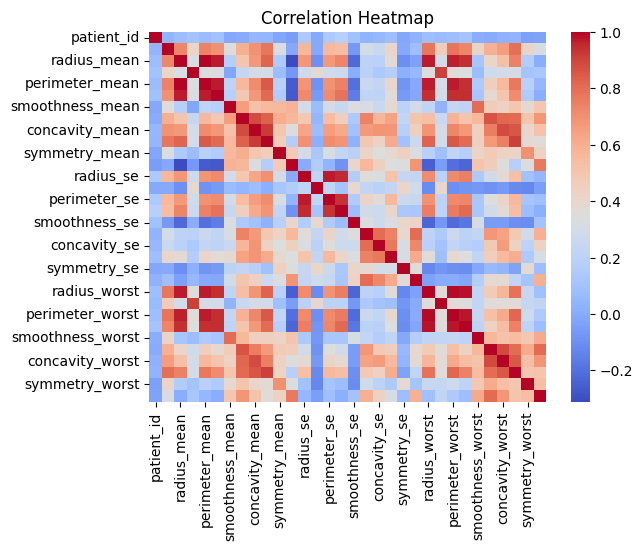

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a correlation matrix
corr_matrix = observations.corr()

# Plot the correlation matrix as a heatmap
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Based on the patient_id feature's name, typical values (very large integers) and weak correlation with all other features, let's go ahead and delete the whole column.

We can carry out the deletion using the DataFrame's `.drop()` method, which we've met before as part of the basic recipe:

In [30]:
observations = observations.drop(columns='patient_id')

Add some code to let you see how the DataFrame is now looking. Options include calling `print()` on it directly, or on the `.info()` method, or on the `.head()` method (which just shows the first few rows):

In [31]:
# Add your code on the line below:
observations.info()
observations.head()


<class 'pandas.core.frame.DataFrame'>
Index: 570 entries, 0 to 574
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                570 non-null    int64  
 1   radius_mean              570 non-null    float64
 2   texture_mean             570 non-null    float64
 3   perimeter_mean           570 non-null    float64
 4   area_mean                570 non-null    float64
 5   smoothness_mean          570 non-null    float64
 6   compactness_mean         570 non-null    float64
 7   concavity_mean           570 non-null    float64
 8   concave points_mean      570 non-null    float64
 9   symmetry_mean            570 non-null    float64
 10  fractal_dimension_mean   570 non-null    float64
 11  radius_se                570 non-null    float64
 12  texture_se               570 non-null    float64
 13  perimeter_se             570 non-null    float64
 14  area_se                  570 no

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,0,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,15.110,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259
1,0,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,14.500,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183
2,0,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,10.230,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773
3,0,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,13.300,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169
4,0,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,8.964,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409


## Converting data types



### Numerical to categorical

Below, we print the DataFrame's `.dtypes` property to see the data type of each column.

Note that they are all numeric. This is fine in terms of our predictive features, but we would expect a categorical target feature:

In [32]:
print(observations.dtypes)

diagnosis                    int64
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst            float64
concave points_worst

We can make this conversion by using the DataFrame's `replace()` method:

In [33]:
observations['diagnosis'] = observations['diagnosis'].replace({0: 'Benign', 1: 'Malignant'})

Add some code to print the `.dtypes` property again, and confirm the relevant column now contains data of type `object` (strings):

In [35]:
# Add your code on the line below

observations.info()

<class 'pandas.core.frame.DataFrame'>
Index: 570 entries, 0 to 574
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                570 non-null    object 
 1   radius_mean              570 non-null    float64
 2   texture_mean             570 non-null    float64
 3   perimeter_mean           570 non-null    float64
 4   area_mean                570 non-null    float64
 5   smoothness_mean          570 non-null    float64
 6   compactness_mean         570 non-null    float64
 7   concavity_mean           570 non-null    float64
 8   concave points_mean      570 non-null    float64
 9   symmetry_mean            570 non-null    float64
 10  fractal_dimension_mean   570 non-null    float64
 11  radius_se                570 non-null    float64
 12  texture_se               570 non-null    float64
 13  perimeter_se             570 non-null    float64
 14  area_se                  570 no

### Categorical to numerical

It's not necessary for the biopsies data, but another commonly required step is to convert a categorical predictive feature into a numerical one. To see how this can be done, let's take a copy of our observations and try to undo the conversion we just did above.

We use the `.get_dummies()` function:

In [36]:
# Take a copy of our DataFrame
observations_copy = pd.DataFrame(observations)
# Convert the categorical variable
dummies = pd.get_dummies(observations_copy['diagnosis'], dtype=float)
print(dummies)

     Benign  Malignant
0       1.0        0.0
1       1.0        0.0
2       1.0        0.0
3       1.0        0.0
4       1.0        0.0
..      ...        ...
570     0.0        1.0
571     0.0        1.0
572     0.0        1.0
573     0.0        1.0
574     0.0        1.0

[570 rows x 2 columns]


The result might look surprising because two columns have been generated: one holds a 1 when the original value was Benign (otherwise zero), the other holds a 1 when the original value was Malignant (otherwise zero). This is called "one-hot encoding".

Performing one-hot encoding is important because it ensures that different category values look equally different to one another from the perspective of a model.

If we just convert categories straight to numerical values in a single column (e.g., 1, 2, 3 and 4) then the problem is that category 3 looks more similar to category 4 than category 1 does (just because they're closer on the number line), when in fact they're both equally different. One-hot coding solves this problem.

(There are cases where it is appropriate to use direct conversion to unique numbers. This is typically when categories are ordered and the difference between consecutive category values is constant (e.g., if you had categories of 'low', 'medium', and 'high'). In these cases you can just use the `.replace()` method as we did above.)

The final step is to replace the original categorical feature with the new numerical features. Again, we've shown how to do this on our copy of the data below, to give the idea, but it isn't something we actually need to do for the biopsies data:

In [37]:
observations_copy['diagnosis_Benign'] = dummies['Benign']
observations_copy['diagnosis_Malignant'] = dummies['Malignant']
observations_copy = observations_copy.drop(columns='diagnosis')
print(observations_copy)

     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0         13.540         14.36           87.46      566.3          0.09779   
1         13.080         15.71           85.63      520.0          0.10750   
2          9.504         12.44           60.34      273.9          0.10240   
3         13.030         18.42           82.61      523.8          0.08983   
4          8.196         16.84           51.71      201.9          0.08600   
..           ...           ...             ...        ...              ...   
570       20.920         25.09          143.00     1347.0          0.10990   
571       21.560         22.39          142.00     1479.0          0.11100   
572       20.130         28.25          131.20     1261.0          0.09780   
573       16.600         28.08          108.30      858.1          0.08455   
574       20.600         29.33          140.10     1265.0          0.11780   

     compactness_mean  concavity_mean  concave points_mean  sym

## Errors








### In categorical data

Spotting errors in data can be very tricky, especially if you have a lot of it. Let's start by looking at the categorical target feature values where errors are relatively easy to find (in our data there are only two possible values).

And let's introduce a typical problem - a typo in one of the labels (e.g., someone hit the wrong keyboard key when originally logging an observation):


In [38]:
# Introduce a typo, as an illustration
observations.loc[430, 'diagnosis'] = 'Nalignant'

You can see a useful summary of the unique values in a column of categorical feature values using the `value_counts()` method:

In [39]:
print(observations['diagnosis'].value_counts())

diagnosis
Benign       358
Malignant    211
Nalignant      1
Name: count, dtype: int64


When you see a small number of obvious typo errors like this one, it's usually fine to just fix them (e.g., if just a single letter in a longer word is incorrect, or there is a capitalisation error):

In [40]:
observations['diagnosis'] = observations['diagnosis'].replace('Nalignant', 'Malignant')
print(observations['diagnosis'].value_counts())

diagnosis
Benign       358
Malignant    212
Name: count, dtype: int64


But if you want to be cautious then you can delete the corresponding observations instead, just as we did when we had a missing feature value.

### In numerical data

Errors in numerical data can be much harder to deal with. Finding numerical feature values that are statistical outliers is relatively easy, but that doesn't necessarily mean they're errors. Making a decision about whether to remove them would typically require a conversation with a domain expert (a clinician, in our case).

For example, have a look at the "box and whisker plot" below. Each box shows the median and upper and lower [quartile](https://en.wikipedia.org/wiki/Quartile) for each feature. 'Whiskers' then connect to the first values within 1.5 * the [interquartile range](https://en.wikipedia.org/wiki/Interquartile_range) from the top and bottom of each box. All feature values beyond the whiskers are plotted as "outliers" (black circles).

They are outliers in the statistical sense (unusual given robust measures of the data dispersion, like the interquartile range) but this doesn't mean they are definitely errors. They may be providing important (but unusual) information about the underlying problem.



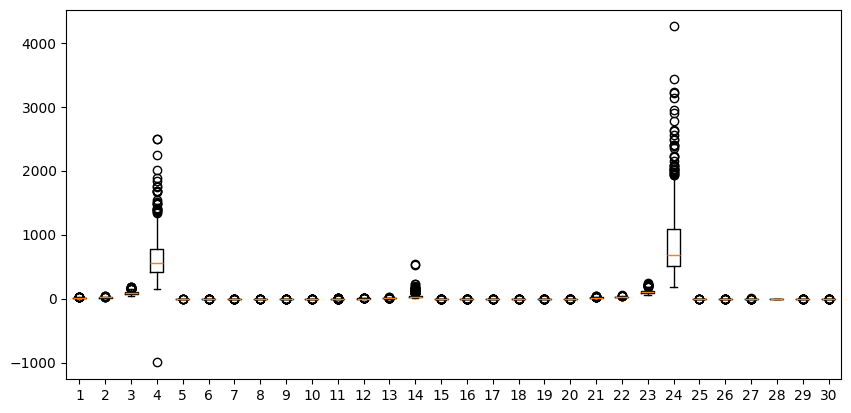

In [41]:
import matplotlib.pyplot as plt

examples = observations.drop(columns='diagnosis')

# Set the figure size
plt.figure(figsize=(10, 4.8))

# Create the boxplot
plt.boxplot(examples)
plt.show()

There are some exceptions, however. For example, we can see that there is a negative feature value for the fourth numerical feature: area_mean. This is an average measure of the area covered by a tissue sample.

Because we know that an area can't be negative, it's safe for us to treat the feature value as an error, and delete the associated observation:

In [42]:
observations = observations[observations['area_mean'] >= 0]

The DataFrame's `.describe()` method provides a useful statistical summary of any numerical columns. Print it out to confirm there are no longer any negative values for the area_mean feature.

In [43]:
# Add your code on the line below
observations.describe()


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


We've now finished cleaning the raw data, and our final DataFrame should be equivalent to loading the biopsies.csv data that we've been working with in previous labs. Let's test this:

In [44]:
# Loading all the cleaned observations (as a Pandas DataFrame)
observations2 = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# reset the index on our dataframe:
observations = observations.reset_index(drop=True)

# Compare our manually cleaned DataFrame to check for equivalence
print(observations.equals(observations2))

True


# Data splitting

## Stratified sampling

The next big job is to split the data. We do this below, using our usual approach (shuffling the data before doing our horizontal and vertical splits):

**Note**: we revert here to loading up the clean data so the code works regardless of whether the cleaning steps above have been run.

In [57]:
# Import the packages we need
import pandas as pd
import numpy as np

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

Let's look at the ratio between the different labels in the original observations, and in the two new partitions:

**Tip**: notice we have to get the label counts in a different way for the two new variables, because they are NumPy arrays. NumPy's `.unique()` function is a handy one to know about (and notice you can ask for the counts of each unique value as well).

**Tip**: Note we're using an improved approach to printing debug here, called "formatted string literals" or "f-strings". They let us refer directly to our variables from the strings we're printing out in debug (we just precede the string with an `f`-character and then use `{}`-braces to refer to variables) and they also let us format their output appropriately (`:.2f` asks for floating point formatting, to 2 decimal places). That's pretty much all you need to know but you can refer to the [Python documentation](https://docs.python.org/3/tutorial/inputoutput.html) if you *want* to know more.

In [58]:
# Get the label counts
observation_counts = observations['diagnosis'].value_counts()
train_unique, train_counts = np.unique(train_labels, return_counts=True)
test_unique, test_counts = np.unique(test_labels, return_counts=True)
# Print ratios (Benign to Malignant)
print(f"The ratio in the observations is: {observation_counts.values[0] / observation_counts.values[1]:.2f}")
print(f"The ratio in the training data is: {train_counts[0] / train_counts[1]:.2f}")
print(f"The ratio in the testing data is: {test_counts[0] / test_counts[1]:.2f}")

The ratio in the observations is: 1.68
The ratio in the training data is: 1.74
The ratio in the testing data is: 1.61


The ratios are fairly similar, but they don't match exactly. On average, a shuffle and split should produce similar ratios in both the resulting partitions (e.g., if we repeat our shuffle and split many times and compute the mean label counts), but because we only do it once, there's a *chance* we can end up with an unusual division of our labels (and their associated examples).

This chance gets greater where there is significantly more of one label in the data than another. We call this kind of data "imbalanced" data. If there are only a small number of a particular label then it becomes much easier, statistically speaking, for the random shuffle to produce a partition that doesn't contain enough of those labels (perhaps even none of them!).

It would be desirable to ensure that the fractions of different labels are preserved across both our partitions. "Stratified sampling" does exactly this by dividing up example-label pairs based on their associated labels, and then randomly sampling pairs with the relevant labels, based on the label fractions seen in the original data.

We can do stratified sampling by doing a single vertical split to separate all our examples from their associated labels, and then calling Scikit-learn's `train_test_split()` helper function to perform the same random shuffle on both, followed by two horizontal splits. We just need to supply the complete set of original labels again via an extra `stratify` argument (from which the function will compute the desired ratio of labels in each new partition); have a look at the example below:

In [59]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Split into examples and labels
examples = observations.drop(columns=target_feature).to_numpy()
labels = observations[target_feature].to_numpy()

# Shuffle and split into training data (60%) and testing data (40%)
train_examples, test_examples, train_labels, test_labels = train_test_split(
    examples,
    labels,
    test_size=0.4,
    random_state=99,
    shuffle=True,
    stratify=labels  # used to calculate the stratification ratios
)

Add code below to print out the label ratios for the original observations and for the new `train_labels` and `test_labels` variables, displaying them each to 3 decimal places:

**Tip**: you can copy/paste the `.value_counts()` / `.unique()` debug from the last code cell but one as your starting point.

**Tip**: They should all match (down to the precision allowed by the number of elements in each array - and these small differences should be revealed by the third decimal place).

In [60]:
# Add your code on the lines below
# Function to print label ratios
def print_ratios(name, data):
    unique, counts = np.unique(data, return_counts=True)
    ratios = counts / len(data)

    print(name)
    for i in range(len(unique)):
        print(f"{unique[i]}: {ratios[i]:.3f}")
    print()


# Original labels ratios
print_ratios("Original labels:", labels)

# Training labels ratios
print_ratios("Train labels:", train_labels)

# Testing labels ratios
print_ratios("Test labels:", test_labels)



Original labels:
Benign: 0.627
Malignant: 0.373

Train labels:
Benign: 0.628
Malignant: 0.372

Test labels:
Benign: 0.627
Malignant: 0.373



## Validation data

Another simple improvement we can make to our recipe is to introduce "validation data". The basic idea here is that what we have previously called "testing data", should be set aside right until the very end of a project for a _single_ final evaluation step, once all the decisions about model choices and hyperparameter settings have been taken. This approach should prevent indirect data leakage (information about the testing data influencing the model training), and give us a robust estimate of expected future performance.

All our investigative work must now be done within the training data, and to allow this we further split it into training data plus "validation data". We'll evaluate on the validation data in the way we *used* to evaluate on our testing data. Meanwhile, our testing data will be kept safely aside for a single model evaluation right at the end of our investigation.

Let's look briefly at the theory, below, but we're ultimately going to meet an even better approach in the later sections:

**Tip**: The extra split should also be done using stratified sampling.

In [61]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Split into examples and labels
examples = observations.drop(columns=target_feature).to_numpy()
labels = observations[target_feature].to_numpy()

# Shuffle and split into training/validation data (80%) and testing data (20%)
non_test_examples, test_examples, non_test_labels, test_labels = train_test_split(
    examples,
    labels,
    test_size=0.2,
    random_state=99,
    shuffle=True,
    stratify=labels  # used to calculate the stratification ratios
)

# Shuffle and split into training data (60%) and testing data (20%)
train_examples, validate_examples, train_labels, validate_labels = train_test_split(
    non_test_examples,
    non_test_labels,
    test_size=0.25,
    random_state=99,
    shuffle=True,
    stratify=non_test_labels  # notice the new final argument
)

# recipe continues as normal, but:
# test_examples -> validate_examples
# test_labels -> validate_labels

# once we've made ALL our decisions about which models and hyperparameters are best for this problem...

# ...we then we re-train on train_examples + validate_examples and train_labels + validate_labels...
# (these are already combined in the non_test_examples and non_test_labels arrays)

# ...and do one final evalution on the test_examples and test_labels (and STOP)...
# ...This final evaluation provides a robust estimate of the model's expected future performance

This is a good and simple change we can make to our basic recipe, but the next sections discuss how we can do even better...

## k-fold cross-validation

The results we get with the training/validation data approach described above can still be sensitive to the initial shuffle and split (even though it's now stratified). For example, if you were to complete an investigation and then go back and change the `random_state` value in the `train_test_split()` call at the top of your notebook, and then re-run it, you may see a very different result.

This is just down to the particular random division of example/label pairs across the different data partitions.

An obvious thing to try is to repeat your investigations several times, with different random seeds, and then take an average. You can imagine all of your investigation code going into a for loop with a change to the `random_state` seed at every iteration. This approach is called "repeated holdout", and it is indeed a better approach than the basic holdout approach we've used so far. However, we can do even better still...

With repeated holdout, there will still be some example/label pairs which are used more/less in the training of your models than others (and same again in the evaluation). "k-Fold cross validation" addresses this issue, making sure every example/label pair is equally important in both the training and evaluation of your models.

The approach is to split your non-testing data into k equally sized partitions, or "folds" and then perform a separate evaluation on each individual fold, while training your model on each of the other k-1 folds. This ensures every single one of your example/label pairs is used the same number of times in model training (k-1 times) and also in model evaluation (1 time).

k-fold cross validation is the gold standard approach to using validation data in a supervised learning recipe, and the good news is that Scikit-learn can generate folds for you, including generating folds using stratified sampling (rather than by sampling purely at random).

Let's have a look at some code, and then we'll discuss it further below:

In [62]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Split into examples and labels
examples = observations.drop(columns=target_feature).to_numpy()
labels = observations[target_feature].to_numpy()

# Shuffle and split into training/validation data (80%) and testing data (20%)
non_test_examples, test_examples, non_test_labels, test_labels = train_test_split(
    examples,
    labels,
    test_size=0.2,
    random_state=99,
    shuffle=True,
    stratify=labels  # used to calculate the stratification ratios
)

# Set up a StratifiedKFold object ready to figure out the indices of the example/label pairs in 5 different folds, using stratified sampling
skf = StratifiedKFold(n_splits=5)

# Generate the indices for each fold, maintining the label ratios seen in non_test_labels
indices = list(skf.split(non_test_examples, non_test_labels))

# uncomment to see the indices printed out (split() returns a generator)
#for i, (train_indices, test_indices) in enumerate(indices):
#  print(f"Fold: {i}")
#  print(f"Train indices: {train_indices}")
#  print(f"Test indices: {test_indices}")

# Create a k-nearest neighbours classifier
model = KNeighborsClassifier(n_neighbors=3)

# calculate the accuracy scores for each of the 5 folds, using k-fold cross validation, and return them in an array
accuracies = cross_val_score(model, non_test_examples, non_test_labels, cv=indices, scoring='accuracy')

# Display all the accuracies, one per fold
print(accuracies)

# Display the average accuracy
print(f"Average accuracy: {np.mean(accuracies):.3f} (or {np.mean(accuracies) * 100:.1f}%)")

# recipe continues as normal, but using cross_val_score for each model/hyperparameter investigation

# once we've made ALL our decisions about which models and hyperparameters are best for this problem...

# ...we then we re-train on all of non_test_examples + non_test_labels

# ...and do one final evalution on the test_examples and test_labels, without cross-validation (and STOP)...
# ...This final evaluation provides a robust estimate of the model's expected future performance

[0.94505495 0.9010989  0.94505495 0.93406593 0.93406593]
Average accuracy: 0.932 (or 93.2%)


We set aside our testing data as before, using a call to `train_test_split()`. However, we *don't* then split the non-testing data as we did earlier. Instead, we create a `StratifiedKFold` object, and use it to generate indices for each of the folds (we ask to use 5), using stratified sampling based on the ratio of different labels in `non_test_lables`. We then make a model, and pass that model, along with the data and the indices for each fold, to the `cross_val_score()` method. This method evaluates the supplied model on each of the 5 folds, by training it on each of the remaining 4 folds. The evaluation metric is supplied by us and here we have asked to use the basic accuracy score we're used to from previous labs (there are a whole range of other options available [here](https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter) - more on these later).

Note that we now get back _a set of 5 different accuracies_, one for each of the 5 different versions of the model that were trained (and evaluated on each of the 5 different folds). We finish by calculating and reporting the average accuracy, as an overall measure of the model's performance on our data.

## Standardisation: a problem

We have some nice simple syntax for doing cross-validation, above. However, there is unfortunately a problem...

Recall that in our original basic recipe, due to the sensitivity of some models to different feature ranges, we needed to standardise the ranges of each of the features in our data. Here's a reminder of the relevant code:

```
from sklearn.preprocessing import StandardScaler

# ...After splitting your data and before fitting your model...

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)
```

In the original recipe, this was a one-time job: learning the transformation from the training data (using `.fit()`), and then applying the transformation to the training data, and then applying the same transformation to the testing data (using `.transform()`).

With our new k-fold cross validation approach, we need to learn and apply a separate transformation *for each of the k evaluations*: learning the transformation from the k-1 training folds, and then applying the transformation to the k-1 training folds, and then applying the same transformation to the kth validation fold.

Sadly, there is no way to ask the `cross_val_score()` method to do this for us.

Our only option would be to loop over the indices produced by the `StratifiedKFold` object, manually (with a for loop, or similar), performing the k-fold cross validation train/test iterations for ourselves, and learning and applying the relevant standardisation transformations each time. This is quite a lot of work! (There's an opportunity to try it in the extension tasks if you're interested.)

Alternatively, there is a quite powerful alternative approach within Scikit-learn that solves this problem for us.

## Pipelines: a solution

Scikit-learn's `Pipeline` class lets you chain together data preprocessing steps (like standardisation) with supervised learning models (like the k-nearest neighbours classifier).

The nicest thing about a `Pipeline` object is that it behaves just like the model objects that we're already used to working with. So we can call `.fit()` and `.predict()` on a `Pipeline` object, and generally just think about them as being normal models, just with some preprocessing steps built-in.

Have a look at the following example which adjusts our original basic recipe code to use a pipeline which combines a k-NN classifier with z-score standardisation:

In [63]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Split into examples and labels
examples = observations.drop(columns=target_feature).to_numpy()
labels = observations[target_feature].to_numpy()

# Shuffle and split into training data (60%) and testing data (40%)
train_examples, test_examples, train_labels, test_labels = train_test_split(
    examples,
    labels,
    test_size=0.4,
    random_state=99,
    shuffle=True
)

# Create a pipeline combining our model with our preprocessing step
pipeline = Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=3))])

# Fit the pipeline to our training data
pipeline.fit(train_examples, train_labels)

# Use the pipeline to generate predictions for our testing examples
predictions = pipeline.predict(test_examples)

# Calculate the pipeline's accuracy - the fraction of predictions that were correct
accuracy = accuracy_score(test_labels, predictions)
print(f"Average accuracy: {accuracy:.3f} (or {accuracy * 100:.1f}%)")

Average accuracy: 0.974 (or 97.4%)


Even better, if you pass a `Pipeline` object to a more complex function like `cross_val_score()`, the preprocessing step will be properly handled for you, which in our case means that the k different independent applications of the standardisation step will be performed for us!

The code listing below shows the earlier k-fold cross validation approach we developed. See if you can fix it so that z-score standardisation is being used appropriately during every model training/evaluation step (there are 5 in total):

**Tip:** The solution is easy if you use a pipeline. You can follow the previous example for guidance.

In [64]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Split into examples and labels
examples = observations.drop(columns=target_feature).to_numpy()
labels = observations[target_feature].to_numpy()

# Shuffle and split into training/validation data (80%) and testing data (20%)
non_test_examples, test_examples, non_test_labels, test_labels = train_test_split(
    examples,
    labels,
    test_size=0.2,
    random_state=99,
    shuffle=True,
    stratify=labels  # used to calculate the stratification ratios
)

# Set up a StratifiedKFold object ready to figure out the indices of the example/label pairs in 5 different folds, using stratified sampling
skf = StratifiedKFold(n_splits=5)

# Generate the indices for each fold, maintining the label ratios seen in non_test_labels
indices = list(skf.split(non_test_examples, non_test_labels))

# Create a k-nearest neighbours classifier
model = KNeighborsClassifier(n_neighbors=3)

# calculate the accuracy scores for each of the 5 folds, using k-fold cross validation, and return them in an array
accuracies = cross_val_score(model, non_test_examples, non_test_labels, cv=indices, scoring='accuracy')

# Display all the accuracies, one per fold
print(accuracies)

# Display the average accuracy
print(f"Average accuracy: {np.mean(accuracies):.3f} (or {np.mean(accuracies) * 100:.1f}%)")

[0.94505495 0.9010989  0.94505495 0.93406593 0.93406593]
Average accuracy: 0.932 (or 93.2%)


# Better model evaluation (2)

So far on this module we've worked only with _accuracy_ as a numerical measure of classification model performance. We've occasionally calculated and looked at confusion matrices, but we haven't done anything useful with them yet. In the following sections we'll introduce some better approaches for measuring the performance of binary classification problems in particular. (They are all also relevant to multiclass problems too.)

## Basic supervised learning recipe

**In the code below we revert back to our familiar basic supervised learning recipe once again. We're going to focus on the model evaluation step at the end of the recipe, without worrying about all the extra data cleaning/splitting steps we've just been discussing above. There's a section at the end encouraging you to think about how to link up these two distinct sets of improvements for your 2CWK50 submission.**

We're processing the (already cleaned) biopsies.csv data once again, and note that rather than calculating accuracy at the end, we generate a confusion matrix instead - which we're going to use to extract some alternative performance metrics:

**Tip:** we're using a k-NN classification model, which is sensitive to predictive feature ranges, so notice that we're using z-score standardisation.

In [65]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

# Set the name of the target feature
target_feature = 'diagnosis'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Use them to create a k-NN classifier
model = KNeighborsClassifier()

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Display a confusion matrix showing a breakdown of results for each label
cm = confusion_matrix(test_labels, predictions)
print(cm)

[[136   4]
 [  5  82]]


## Confusion matrices

Assuming that Malignant is the positive class label, answer the following questions:

*    How many True Negatives (TN) were there? ** 136**
*    How many False Positives (FP) were there? ** 4**
*    How many False Negatives (FN) were there? ** 5**
*    How many True Positives (TP) were there? ** 82**

**Tip**: Have a look at this week's notes slides if you need help.

**Tip**: If you can't remember how the confusion matrix columns/rows are organised in Scikit-learn, you can check in the `.classes_` property of the model.

## TPR / FPR

By using your answers above, calculate answers to the following questions, showing your working:

*    What was the True Positive Rate (TPR)? **Type your answer here**
*    What was the False Positive Rate (FPR)? **Type your answer here**
*    Add some code to the cell below to calculate both values directly from the values in `cm`

**Tip**: Have a look at this week's notes slides if you need help with the equations.

**Tip**: Both your results should be in the range 0-1.

**Tip**: Remember you can access the elements of a 2D NumPy array like `cm` using notation like `cm[0,0]` for the top left element, and `cm[1,1]` for the bottom right element, etc.

In [67]:
# Uncomment and complete the following lines

TP = 82;
FP = 4;
TN = 136;
FN = 5;

# True Positive Rate (Recall / Sensitivity)
TPR = TP / (TP + FN)

# False Positive Rate
FPR = FP / (FP + TN)

print("TPR =", round(TPR, 3))
print("FPR =", round(FPR, 3))


TPR = 0.943
FPR = 0.029


## ROC curves

We'd like our TPR as close to 1 as possible, and our FPR as close to zero as possible. But remember, the scores we got above are just one part of the overall picture for this model - they only tell us what happens when the probability threshold for predicting the positive class label is 50%.

Receiver operating characteristic (ROC) curves can help us to understand how the TPR/FPR results change for all possible probability thresholds on the positive class label.

*    **Uncomment the commented line in the code listing below so that the TPR/FPR results you calculated above are added to the plot as a single new point**


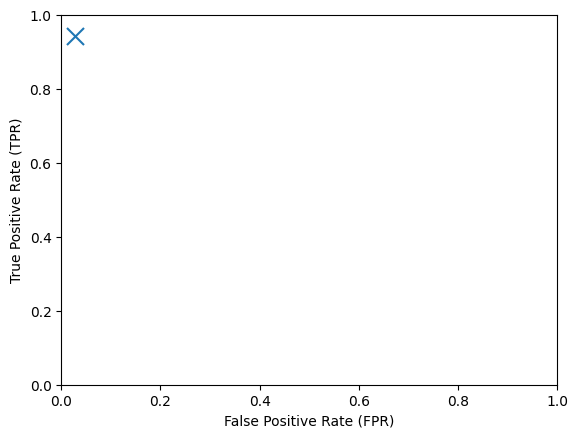

In [68]:
import matplotlib.pyplot as plt

# Visualise our model's performance
plt.figure()
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")

# Scatter our FPR, TPR result (uncomment this line to plot your result)
plt.scatter(FPR, TPR, marker='x', s=150)

plt.show()

Below we find the probabilities for the positive class label in each prediction made by our model, and then use Scikit-learn's built-in `roc_curve()` function to plot the full ROC curve (for all possible probability thresholds on the positive class label).

*    **Uncomment the commented line once again, to put our original result into the context of the full ROC curve**

*    Would you be tempted to adjust the default threshold (of 50%) for predicting the positive class label for this model (give your reasoning)? **Type your answer here**

**Tip**: you're thinking about how close the ROC curve ever gets to the top left hand corner of the plot.

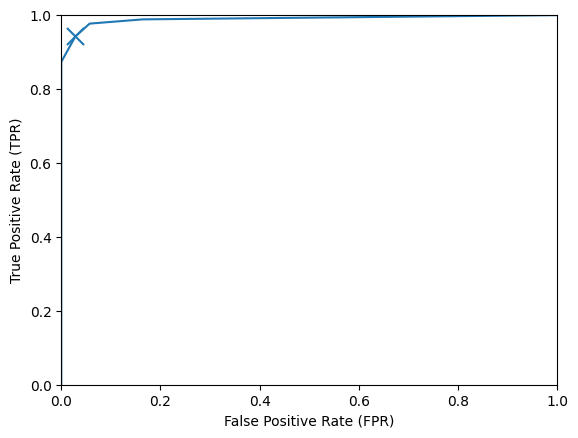

In [69]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# Visualise our model's performance
plt.figure()
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")

# Get probability scores for the positive class for every testing example
pos_index = list(model.classes_).index("Malignant")
scores = model.predict_proba(test_examples)[:, pos_index]

# Compute the full ROC curve
fpr, tpr, _ = roc_curve(test_labels, scores, pos_label="Malignant")

# And plot it
plt.plot(fpr, tpr)

# Scatter our FPR, TPR result in context (uncomment this line to plot your original result)
plt.scatter(FPR, TPR, marker='x', s=150)

plt.show()

## Area under the ROC curve (AUC)

Scikit-learn also has built-in support for finding the area under the ROC curve (AUC), via the function `roc_auc_score()`. This is a _single number_ that encapsulates both the FPR and the TPR (which in turn encapsulate 4 other numbers from our confusion matrix), for _all_ possible probability thresholds on predicting the positive class label. That's a nice evaluation metric!

*    **By first having a look at the relevant documentation - add a line of code below to calculate the AUC score for this model**

**Tip**: many other evaluation metrics are available; have a look at the [`sklearn.metrics` documentation](https://scikit-learn.org/stable/api/sklearn.metrics.html) for other options, and also for how to get AUC for multiclass problems.

In [71]:
# Add your code on the line below

from sklearn.metrics import roc_auc_score

auc = roc_auc_score(test_labels, scores)
print("AUC =", round(auc, 3))



AUC = 0.99


# Bringing it all together (3)

In your own model investigations, you will want to bring together the good practice identified in part (1) - e.g., data cleaning, k-fold cross validation, pipelines, etc. - with the good practice identified in part (2) - better evaluation metrics, ROC curves, AUC, etc.

Remember that when we were calling `cross_val_score()`, we could pass in the evaluation metric we wanted to use via the `scoring` argument. This is a good moment to return to the [other options available](https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter).

If you get deep into investigating multiple hyperparameters, then it's also worth knowing about Scikit-learn's `GridSearchCV()` class. Hyperparameters interact with one another, which means you need to _nest_ your for loops if you're investigating more than one. Rather than you ending up with lots of nested for loops, the `GridSearchCV()` class will let you specify a set of hyperparameters you're interested in varying, and a set of associated ranges over which you wish to vary them. It will then handle all the nested looping over the different options _for you_, in an efficient way.

*    **Rework the very basic evaluation we did of k-NN for the (clean) biopsies.csv data, above, into a full investigation, varying both k _and_ the choice of difference score, and using k-fold cross validation with 5 stratified folds and a better performance metric than accuracy.**

**Tip**: Strong encouragement to use a pipeline in order to apply standardisation correctly (_per fold_).

**Tip**: `GridSearchCV()` also supports a `scoring` argument in just the same way as `cross_score_val()`, if you want to avoid building your own nested for loops to investigate your hyperparameter settings.

**Tip**: You don't need to investigate any other models. How can you prepare the data so that after you have selected the best hyperparameters for k-NN, you are able to generate a robust estimate of expected future performance? What is reasonable to expect in terms of AUC?

In [72]:
# Add your code on the lines below

# Imports
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Load data
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/biopsies.csv')

target_feature = 'diagnosis'

# Split into X and y
X = observations.drop(columns=target_feature)
y = observations[target_feature]

# ----------------------------
# Pipeline (scaling + model)
# ----------------------------
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# ----------------------------
# Parameter grid
# ----------------------------
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9],
    'knn__metric': ['euclidean', 'manhattan']
}

# ----------------------------
# Cross-validation setup
# ----------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=99)

# ----------------------------
# Grid Search
# ----------------------------
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='roc_auc'  # better than accuracy ✅
)

# Fit model
grid.fit(X, y)

# ----------------------------
# Results
# ----------------------------
print("Best parameters:", grid.best_params_)
print("Best AUC:", round(grid.best_score_, 3))




Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 7}
Best AUC: 0.991


# Extension tasks (optional)

(Extension tasks are optional. They don't map to the assessment on this module and there is no harm in skipping them. However, for people who are interested in the subject/planning to do further study, the extension tasks can help you deepen your machine learning knowledge and meet the module learning objectives more fully.)

1. Would you like to write functions implementing any of the various cleaning steps we met? They should all accept and operate on DataFrames. For example, `my_dropna()`, `my_drop_duplicates()`, `my_get_dummies()`, etc.

2. Would you like to write a `my_train_test_split()` function that re-implements the main steps carried out by scikit-learn's `train_test_split()` function? Some suggestions for approaching the re-implementation follow below:
    *   You don't need to accept all the same parameters as the original function straight away - start by accepting `examples` and `labels` only and use sensible
defaults for the other values
    *   The original function will accept `examples` and `labels` as lists, ndarrays, or DataFrames - cater only for ndarrays to begin with (add support for other options later on if you want to)
    *   For the shuffle, remember that the random sequence you use to reorder the `examples` and `labels` must be the same - individual examples and labels must still correspond after the shuffle is complete
    *   You should be able to replace the call to `train_test_split()` in the original code listing with a call to `my_train_test_split()` and see a comparable performance from the model in terms of accuracy (it won't be identical due to the randomness of the shuffle)
    *   Can you extend your function to handle lists/ndarrays/DataFrames, can you extend you function to handle other helpful parameters from the caller?

3. Would you like to extend your `my_train_test_split()` re-implementation (see above) to support a stratified sampling option? You can just stratify by default, on the basis of the supplied labels (and add other options via the arguments later if you wish).

4. Would you like to write a `MyStratifiedKFold` class with a `.split()` method that will return indices for each (stratified) fold? The original class returns a generator, which you may be interested to investigate. But returning a list is equally fine. Have a look at the structure of the generator, recast to a list in the earlier example (there are some print statements to uncomment).

5. Would you like to write a `my_cross_val_score_standard()` function which uses the indices from the `StratifiedKFold` object (or your own `MyStratifiedKFold` object) to perform cross validation manually, and _additionally performs the standardisation step_? The function can be hardcoded to return accuracy (and you could return to add other metrics later).

6. Would you like to write a `my_roc_auc_score()` function which takes the same arguments as Scikit-learn's `roc_auc_score()` and outputs TPR/FPR coordinates ready for plotting an ROC curve? There are extra notes slides showing a step-by-step example.

7. Would you like to write a `MyGridSearchCV()` class which accepts a model, `StratifiedKFold` object (or your own `MyStratifiedKFold` object), a set of hyperparameter names, and a set of associated hyperparameter value ranges, and generates a set of nested loops in order to investigate all possible hyperparameter combinations. The class can be hardcoded to return accuracy (and you could return to add other metrics later).